# California Sierra Nevada rapid snowmelt: event detection using the standard deviation of the distribution of 5-day means

Companion to `CA_snowmelt_events_detrend_5day.ipynb` (snow-side Method A: per-station
**min-in-window** SWE decline -- `min(SWE over 3 days) - SWE at window start`,
standardized per calendar day, network event = >=30% of reporting stations
simultaneously >=1 SD below normal for >=5 consecutive days) and to
`CA_z500_t700_methodC_5daymean_std.ipynb` (the Z500/T700 notebook that first asked:
what if a "large event" is instead defined by the standard deviation of the
distribution of **5-day means**, with persistence baked into the smoothing itself
rather than asserted as a separate >=5-consecutive-day rule?).

**Why this isn't a direct port of Method C.** The Z500/T700 Method C notebook smooths
a genuinely raw daily signal (daily box-averaged Z500/T700) with one centered 5-day
mean. Sierra SWE has no equivalent raw instantaneous daily signal to smooth: the
companion notebook's per-station metric is *already* a derived quantity -- a 3-day
min-in-window decline (originally a 5-day backward difference; the companion notebook
adopted the min-in-window version after its own stress-testing, but the "already a
derived, windowed quantity" problem is the same either way). Taking a centered 5-day
mean of a network fraction built from that would smooth over something closer to 7-8
effective days -- two stacked windows, not one clean "daily value -> 5-day mean"
comparison -- and would conflate "does Method C help" with "does smoothing an
already-smoothed signal further help," which isn't the question.

**This notebook's design avoids that by building a new, genuinely raw daily
substrate just for this comparison**: per-station **1-day** SWE change (not the
companion notebook's 5-day backward difference), standardized per calendar day the
same way. From that single raw daily network-decline-fraction series, three event
definitions are compared side by side:

1. **Method A (headline)** -- the companion notebook's actual result, reproduced here
   for reference: per-station min-in-window decline (3-day window), >=5 consecutive
   network-fraction days >=30%. **58 events, water years 1990-2025.**
2. **Method A' (control)** -- same persistence rule (>=5 consecutive days >=30% of
   network), but built on the raw 1-day diff instead of the companion notebook's
   3-day min-in-window metric. This isolates the effect of the companion notebook's
   derived-metric choice from the Method A-vs-Method-C question below.
3. **Method C** -- the raw daily network-decline-fraction (1-day-diff basis, no
   persistence built in) smoothed with one centered 5-day rolling mean, standardized
   against the calendar-day climatology of *that* distribution, thresholded at
   1/2/3 SD with `min_duration=1` (persistence is now baked into the smoothing itself,
   exactly mirroring how the Z500/T700 Method C notebook treats its own raw daily
   value).

**A caveat baked into this design, not papered over**: Method A and Method A' are NOT
the same baseline -- switching from the companion notebook's 3-day min-in-window
metric to a raw 1-day diff is itself a real methodological change (see Section 3 vs
Section 5), independent of Method A vs Method C. Reporting all three side by side,
rather than only Method A' vs Method C, makes that visible instead of hiding it inside
a single "Method C finds more events" headline.

**Data**: same `combined_sierra_stations.csv` / `combined_sierra_swe_wy1990-2026.csv`
(SNOTEL+MSNT+CDEC, 147 daily-reporting Sierra stations) as the companion notebook --
see that notebook's intro for the full station-network rationale.

## 0. Setup

In [1]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import linregress
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')

CLIM_WINDOW = 5          # +/- calendar days pooled for climatology (matches both companion notebooks)
MIN_DURATION = 5         # Method A / A' persistence requirement: consecutive network-event days
MAX_GAP = 1              # max sub-threshold calendar days tolerated within an event; see Section 10
MIN_SWE_MM = 25.0        # ~1 in -- require this much SWE before counting a decline (matches companion)
ROLL_WINDOW = 5          # width of the centered rolling mean that defines Method C's "5-day mean"
SIGMA = 1.0              # station-day standardized-decline threshold (matches companion notebook's primary series)
NETWORK_THRESH = 0.3     # fraction of reporting Sierra stations in rapid decline -> network event day (Method A/A')
THRESHOLDS = [1, 2, 3]   # standard deviations OF THE 5-DAY-MEAN DISTRIBUTION -- Method C only
YEARS = list(range(1990, 2026))      # fit years -- 2026 not pulled into this comparison
SIGN = 1

SIERRA_LAT_S, SIERRA_LAT_N = 34.5, 40.0
SIERRA_LON_W, SIERRA_LON_E = -121.0, -116.5
MONTH_NAMES = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May'}

print(f'CLIM_WINDOW={CLIM_WINDOW}, ROLL_WINDOW={ROLL_WINDOW}, MIN_DURATION={MIN_DURATION}, MAX_GAP={MAX_GAP}')

CLIM_WINDOW=5, ROLL_WINDOW=5, MIN_DURATION=5, MAX_GAP=1


## 1. Load combined SNOTEL+MSNT+CDEC stations and daily SWE

Identical to the companion notebook's Section 1 -- see that notebook for the full
station-network rationale (why SNOTEL alone misses the southern Sierra, how MSNT/CDEC
fill the gap, and the SNTL/MSNT-over-CDEC-duplicate preference).

In [2]:
stations_csv = DATA_DIR / 'combined_sierra_stations.csv'
swe_csv = DATA_DIR / 'combined_sierra_swe_wy1990-2026.csv'
if not stations_csv.exists() or not swe_csv.exists():
    raise FileNotFoundError(
        f'{stations_csv.name} / {swe_csv.name} missing from {DATA_DIR}.\n'
        'Run get_snotel_box.py, get_msnt_box.py, get_cdec_box.py, qc_cdec_swe.py, '
        'check_msnt_cdec_overlap.py, then build_combined_sierra_swe.py first.'
    )

stations = pd.read_csv(stations_csv).rename(columns={'station_id': 'stationTriplet'})
swe_long = pd.read_csv(swe_csv, parse_dates=['date']).rename(columns={'station_id': 'stationTriplet'})
swe_long = swe_long[swe_long.duration == 'D'].drop(columns=['duration'])

sierra_mask = (
    stations.latitude.between(SIERRA_LAT_S, SIERRA_LAT_N) &
    stations.longitude.between(SIERRA_LON_W, SIERRA_LON_E)
)
sierra_stations = stations[sierra_mask].copy()
daily_ids = set(swe_long.stationTriplet)
n_daily = sierra_stations.stationTriplet.isin(daily_ids).sum()
print(f'{len(sierra_stations)} of {len(stations)} combined stations in the Sierra box, '
      f'{n_daily} reporting at daily resolution (feeds the pipeline below)')


def water_year(dates):
    # Oct-Dec belongs to the following calendar year's water year (NRCS/USGS
    # convention). With everything below restricted to Jan-May, this always
    # reduces to the plain calendar year in practice -- see companion notebook.
    return dates.dt.year + (dates.dt.month >= 10).astype(int)


swe_long = swe_long[swe_long.stationTriplet.isin(sierra_stations.stationTriplet)].copy()
swe_long = swe_long.groupby(['stationTriplet', 'date'], as_index=False)['swe_mm'].mean()
swe = swe_long.pivot(index='date', columns='stationTriplet', values='swe_mm').sort_index()
full_idx = pd.date_range(swe.index.min(), swe.index.max(), freq='D')
swe = swe.reindex(full_idx)
swe.index.name = 'date'

wy = water_year(pd.Series(swe.index))
wy.index = swe.index
print(f'date range: {swe.index.min().date()} to {swe.index.max().date()}, years {wy.min()}-{wy.max()}')

312 of 312 combined stations in the Sierra box, 147 reporting at daily resolution (feeds the pipeline below)


date range: 1989-10-01 to 2026-05-31, years 1990-2026


## 2. Method A (headline): reproduce the companion notebook's min-in-window result

Reproduces `CA_snowmelt_events_detrend_5day.ipynb` Sections 2-3 exactly (same
`MIN_SWE_MM`, the min-in-window decline metric at `WINDOW_A=3` -- `min(SWE over the
window) - SWE at window start`, adopted in that notebook after its own
`MIN_SWE_MM`/`WINDOW`/metric-x-WINDOW stress-testing -- per-station detrended
climatology, `SIGMA=1.0`, `NETWORK_THRESH=0.3`, `MIN_DURATION=5`, `MAX_GAP=1`) so this
notebook has its own copy of the headline baseline to compare against, rather than
trusting an imported CSV to stay in sync.

In [3]:
WINDOW_A = 3   # the companion notebook's min-in-window span (adopted in place of the
               # original 5-day backward difference -- see that notebook's Section 2)

d_A = swe.rolling(WINDOW_A + 1).min() - swe.shift(WINDOW_A)
start_swe_A = swe.shift(WINDOW_A)
d_A = d_A.where(start_swe_A >= MIN_SWE_MM)

fit_mask = wy.isin(YEARS).values
fit_time_index = d_A.index[fit_mask]

m_A, s_A = {}, {}
resid_pool, wy_pool = [], []
for col in d_A.columns:
    clim_mean, clim_std = lib.climatology_dict(fit_time_index, d_A[col].values[fit_mask], window=CLIM_WINDOW,
                                                dropna=True, min_samples=10, check_wraparound=False)
    m_A[col] = lib.lookup_climatology(d_A.index, clim_mean)
    s_A[col] = lib.lookup_climatology(d_A.index, clim_std)
    resid = d_A[col].values[fit_mask] - lib.lookup_climatology(fit_time_index, clim_mean)
    valid = ~np.isnan(resid)
    resid_pool.append(resid[valid])
    wy_pool.append(wy.values[fit_mask][valid])

resid_pool, wy_pool = np.concatenate(resid_pool), np.concatenate(wy_pool)
yearly_resid = pd.Series(resid_pool, index=wy_pool).groupby(level=0).mean()
slope_A, intercept_A, r_A, p_A_trend, se_A = linregress(yearly_resid.index, yearly_resid.values)
trend_A = intercept_A + slope_A * wy.values

sanom_A = pd.DataFrame(index=d_A.index, columns=d_A.columns, dtype=float)
for col in d_A.columns:
    sanom_A[col] = (d_A[col].values - (m_A[col] + trend_A)) / s_A[col]

janmay_mask = d_A.index.month.isin([1, 2, 3, 4, 5])
d_A, sanom_A, wy_A = d_A[janmay_mask], sanom_A[janmay_mask], wy[janmay_mask]
n_reporting_A = d_A.notna().sum(axis=1)
frac_declining_5 = ((sanom_A <= -SIGMA).sum(axis=1) / n_reporting_A.replace(0, np.nan)).fillna(0.0)


def find_events_raw(dates, series, threshold, min_duration, max_gap=MAX_GAP):
    # matches companion notebook's local wrapper: raw-fraction events, not sigma events
    ev = lib.find_events(dates, series.values, threshold=threshold, min_duration=min_duration, sign=SIGN, max_gap=max_gap)
    return ev.rename(columns={'peak_sanom': 'peak_frac', 'mean_sanom': 'mean_frac'}).drop(columns='second_peak_sanom')


ev_A_all = find_events_raw(frac_declining_5.index, frac_declining_5, threshold=NETWORK_THRESH, min_duration=MIN_DURATION)
ev_A_all['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in ev_A_all.start_date]
events_A = ev_A_all[ev_A_all.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)
print(f'Method A (headline, min-in-window WINDOW=3): {len(events_A)} events, water years {YEARS[0]}-{YEARS[-1]} '
      f'(should match the companion notebook)')
events_A[['start_date', 'end_date', 'duration_days', 'peak_frac']].sort_values('start_date')

Method A (headline, min-in-window WINDOW=3): 58 events, water years 1990-2025 (should match the companion notebook)


,start_date,end_date,duration_days,peak_frac
0,1990-03-23,1990-03-27,5,0.444444
1,1990-04-11,1990-04-16,6,0.840909
2,1990-05-04,1990-05-08,5,0.571429
3,1991-02-21,1991-02-27,7,0.447059
4,1992-04-26,1992-05-01,6,0.727273
5,1992-05-07,1992-05-18,12,0.533333
6,1993-05-17,1993-05-24,8,0.459459
7,1994-04-14,1994-04-22,9,0.907407
8,1995-02-24,1995-02-28,5,0.438776
9,1996-02-07,1996-02-18,12,0.404762


## 3. The raw daily substrate: per-station 1-day SWE change

Builds a genuinely raw daily signal -- the per-station **1-day** SWE change (not a
backward-windowed one) -- standardized per calendar day exactly like Section 2's d5,
just with `WINDOW_RAW=1`. This is the quantity Method C (Section 5) will smooth with
one centered 5-day mean; Method A' (Section 4) applies the companion notebook's same
persistence rule directly to it, as a control.

In [4]:
WINDOW_RAW = 1   # raw daily difference -- the thing Method C will smooth

d1 = swe.diff(WINDOW_RAW)
start_swe1 = swe.shift(WINDOW_RAW)
d1 = d1.where(start_swe1 >= MIN_SWE_MM)

m1, s1 = {}, {}
resid_pool, wy_pool = [], []
for col in d1.columns:
    clim_mean, clim_std = lib.climatology_dict(fit_time_index, d1[col].values[fit_mask], window=CLIM_WINDOW,
                                                dropna=True, min_samples=10, check_wraparound=False)
    m1[col] = lib.lookup_climatology(d1.index, clim_mean)
    s1[col] = lib.lookup_climatology(d1.index, clim_std)
    resid = d1[col].values[fit_mask] - lib.lookup_climatology(fit_time_index, clim_mean)
    valid = ~np.isnan(resid)
    resid_pool.append(resid[valid])
    wy_pool.append(wy.values[fit_mask][valid])

resid_pool, wy_pool = np.concatenate(resid_pool), np.concatenate(wy_pool)
yearly_resid = pd.Series(resid_pool, index=wy_pool).groupby(level=0).mean()
slope1, intercept1, r1, p1, se1 = linregress(yearly_resid.index, yearly_resid.values)
print(f'Pooled year-trend in 1-day SWE-change climatology residual: {slope1*10:.3f} mm/day per decade, p={p1:.3f}')
trend1 = intercept1 + slope1 * wy.values

sanom1 = pd.DataFrame(index=d1.index, columns=d1.columns, dtype=float)
for col in d1.columns:
    sanom1[col] = (d1[col].values - (m1[col] + trend1)) / s1[col]

d1, sanom1 = d1[janmay_mask], sanom1[janmay_mask]
n_reporting1 = d1.notna().sum(axis=1)
frac_declining_1 = ((sanom1 <= -SIGMA).sum(axis=1) / n_reporting1.replace(0, np.nan)).fillna(0.0)

print(f'\nfrac_declining (1-day basis): zero-days={int((frac_declining_1==0).sum())} '
      f'({100*(frac_declining_1==0).mean():.1f}%), mean={frac_declining_1.mean():.4f}, '
      f'max={frac_declining_1.max():.4f}, skew={frac_declining_1.skew():.3f}')
print(f'for comparison, frac_declining (5-day-backward-diff basis, Section 2): '
      f'zero-days={100*(frac_declining_5==0).mean():.1f}%, mean={frac_declining_5.mean():.4f}, '
      f'skew={frac_declining_5.skew():.3f}')
print('\nThe 1-day basis is zero on fewer days but has a lower mean and similar skew -- a raw daily '
      'diff is noisier day-to-day (sensor jitter, diurnal melt/refreeze) but any single day rarely '
      'gets as many stations simultaneously over threshold as a 5-day cumulative change does.')

Pooled year-trend in 1-day SWE-change climatology residual: -0.199 mm/day per decade, p=0.599

frac_declining (1-day basis): zero-days=1294 (23.1%), mean=0.0740, max=0.8202, skew=2.506
for comparison, frac_declining (5-day-backward-diff basis, Section 2): zero-days=14.0%, mean=0.1295, skew=1.927

The 1-day basis is zero on fewer days but has a lower mean and similar skew -- a raw daily diff is noisier day-to-day (sensor jitter, diurnal melt/refreeze) but any single day rarely gets as many stations simultaneously over threshold as a 5-day cumulative change does.


## 4. Method A\': same persistence rule, raw 1-day-diff basis (control)

Applies the *exact same* event-detection rule as Method A (>=5 consecutive days with
>=30% of the network in rapid decline) to `frac_declining_1` instead of
`frac_declining_5`. The only thing that changes from Method A is the per-station
window (1-day vs 5-day backward diff) -- this isolates that choice from the Method
A-vs-Method-C question in Sections 5-9.

In [5]:
ev_Ap_all = find_events_raw(frac_declining_1.index, frac_declining_1, threshold=NETWORK_THRESH, min_duration=MIN_DURATION)
ev_Ap_all['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in ev_Ap_all.start_date]
events_Aprime = ev_Ap_all[ev_Ap_all.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)

print(f"Method A' (control, 1-day diff, same persistence rule as Method A): "
      f"{len(events_Aprime)} events, water years {YEARS[0]}-{YEARS[-1]}")
print(f"(Method A itself: {len(events_A)} events -- the gap is purely the 5-day-backward-diff vs "
      f"1-day-diff choice, since the persistence rule is identical)")
events_Aprime[['start_date', 'end_date', 'duration_days', 'peak_frac']].sort_values('start_date')

Method A' (control, 1-day diff, same persistence rule as Method A): 25 events, water years 1990-2025
(Method A itself: 58 events -- the gap is purely the 5-day-backward-diff vs 1-day-diff choice, since the persistence rule is identical)


,start_date,end_date,duration_days,peak_frac
0,1990-04-10,1990-04-15,6,0.704545
1,1994-04-13,1994-04-21,9,0.678571
2,1997-03-19,1997-03-27,9,0.545455
3,1997-04-16,1997-04-22,7,0.462366
4,1997-05-04,1997-05-17,14,0.586957
5,2001-05-07,2001-05-11,5,0.405405
6,2001-05-21,2001-05-25,5,0.526316
7,2002-04-01,2002-04-05,5,0.490566
8,2002-04-11,2002-04-15,5,0.750000
9,2003-05-27,2003-05-31,5,0.507692


## 5. Method C: the distribution of 5-day means of the raw daily fraction

Takes a centered 5-day rolling mean of `frac_declining_1` (one smoothing pass over a
genuinely raw daily signal -- see Section 3), then standardizes *that* series against
its own calendar-day climatology (detrended, same `CLIM_WINDOW` as Methods A/A').
`lib.standardize_with_trend` reports the naive-vs-corrected clim_std fix size as it
runs.

In [6]:
frac_roll = lib.rolling_mean_per_year(frac_declining_1, ROLL_WINDOW).dropna()  # drops each year's edge days

sanom_daily, diag_daily = lib.standardize_with_trend(frac_declining_1.index, frac_declining_1.values,
                                                      window=CLIM_WINDOW, label='frac_declining (1-day, daily)')
sanom_roll, diag_roll = lib.standardize_with_trend(frac_roll.index, frac_roll.values,
                                                    window=CLIM_WINDOW, label='frac_declining (1-day, 5-day mean)')

daily_std = diag_daily['clim_std'].mean()
roll_std = diag_roll['clim_std'].mean()
pct = 100 * (1 - roll_std / daily_std)
print(f'\nStandard deviation of the distribution of values (dimensionless fraction), '
      f'averaged across all calendar-day windows:')
print(f'  daily          = {daily_std:.4f}')
print(f'  5-day mean     = {roll_std:.4f}  ({pct:.1f}% narrower)')
print(f'\nSkewness (0 = symmetric): daily frac={frac_declining_1.skew():.3f}, '
      f'5-day-mean frac={frac_roll.skew():.3f}, daily sanom={pd.Series(sanom_daily).skew():.3f}, '
      f'5-day-mean sanom={pd.Series(sanom_roll).skew():.3f}')
print('Still clearly right-skewed either way (a bounded, zero-heavy network fraction, not a '
      'free-ranging physical field like Z500/T700) -- see Section 7 for a distribution-free cross-check.')

frac_declining (1-day, daily): Theil-Sen trend = +0.004/decade (90% CI [-0.005, +0.011]/decade); OLS = +0.004/decade (p=0.425, r=0.14)
frac_declining (1-day, daily): clim_std, naive (trend-contaminated) = 0.0898, detrended (corrected) = 0.0898 (+0.044% difference)
frac_declining (1-day, 5-day mean): Theil-Sen trend = +0.003/decade (90% CI [-0.005, +0.011]/decade); OLS = +0.004/decade (p=0.414, r=0.14)
frac_declining (1-day, 5-day mean): clim_std, naive (trend-contaminated) = 0.0743, detrended (corrected) = 0.0743 (+0.057% difference)

Standard deviation of the distribution of values (dimensionless fraction), averaged across all calendar-day windows:
  daily          = 0.0898
  5-day mean     = 0.0743  (17.3% narrower)

Skewness (0 = symmetric): daily frac=2.506, 5-day-mean frac=2.334, daily sanom=2.438, 5-day-mean sanom=1.841
Still clearly right-skewed either way (a bounded, zero-heavy network fraction, not a free-ranging physical field like Z500/T700) -- see Section 7 for a distributi

## 6. How much narrower, with a bootstrap confidence interval

Same year-block bootstrap as the Z500/T700 Method C notebook (and this project's own
`MIN_SWE_MM` sensitivity check): resample the 36 years with replacement, paired draws
(shared `random_state`) between the daily and 5-day-mean series so the "% narrower"
statistic gets a real confidence interval, not a bare point estimate.

In [7]:
N_BOOT = 200
boot_daily, ci_daily = lib.bootstrap_climatology_std(frac_declining_1.index, frac_declining_1.values,
                                                      window=CLIM_WINDOW, n_boot=N_BOOT, random_state=0)
boot_roll, ci_roll = lib.bootstrap_climatology_std(frac_roll.index, frac_roll.values,
                                                    window=CLIM_WINDOW, n_boot=N_BOOT, random_state=0)
pct_boot = 100 * (1 - boot_roll / boot_daily)
lo, hi = np.percentile(pct_boot, [5, 95])
point = 100 * (1 - boot_roll.mean() / boot_daily.mean())
print(f'{point:.1f}% narrower (90% bootstrap CI [{lo:.1f}%, {hi:.1f}%]), n_boot={N_BOOT}')
print(f'  daily clim_std:      {boot_daily.mean():.4f}, 90% CI {ci_daily[0]:.4f}-{ci_daily[1]:.4f}')
print(f'  5-day-mean clim_std: {boot_roll.mean():.4f}, 90% CI {ci_roll[0]:.4f}-{ci_roll[1]:.4f}')

17.6% narrower (90% bootstrap CI [15.4%, 20.2%]), n_boot=200
  daily clim_std:      0.0880, 90% CI 0.0771-0.0990
  5-day-mean clim_std: 0.0726, 90% CI 0.0618-0.0830


## 7. Histogram: daily fraction vs. the distribution of 5-day means

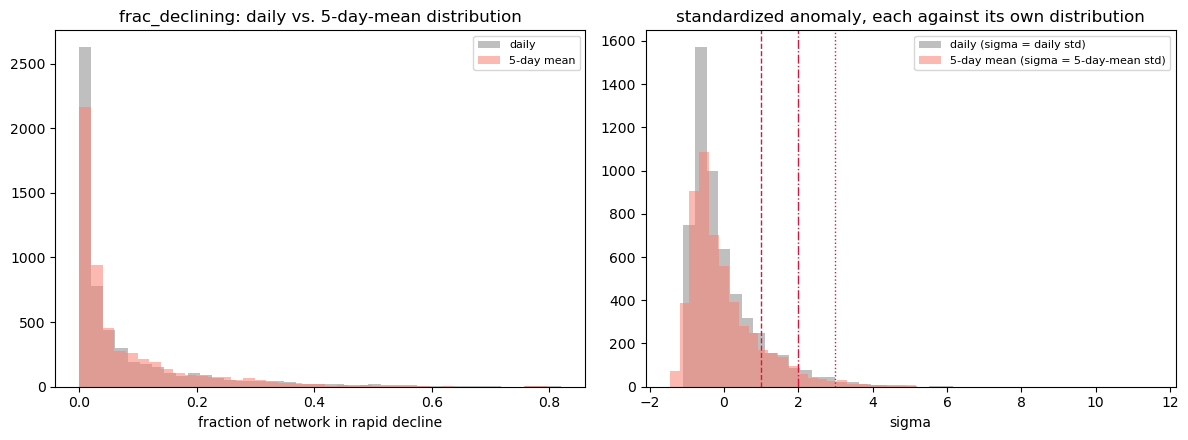

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(frac_declining_1, bins=40, color='grey', alpha=0.5, label='daily')
axes[0].hist(frac_roll, bins=40, color='salmon', alpha=0.55, label='5-day mean')
axes[0].set_title('frac_declining: daily vs. 5-day-mean distribution')
axes[0].set_xlabel('fraction of network in rapid decline')
axes[0].legend(fontsize=8)

axes[1].hist(sanom_daily, bins=40, color='grey', alpha=0.5, label='daily (sigma = daily std)')
axes[1].hist(sanom_roll, bins=40, color='salmon', alpha=0.55, label='5-day mean (sigma = 5-day-mean std)')
for sd, ls in zip(THRESHOLDS, ['--', '-.', ':']):
    axes[1].axvline(sd, color='crimson', linestyle=ls, linewidth=1)
axes[1].set_title('standardized anomaly, each against its own distribution')
axes[1].set_xlabel('sigma')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Method C events: thresholding the 5-day-mean distribution

Each day of `frac_roll` already *is* a 5-day mean, so persistence is baked into the
quantity itself -- `min_duration=1` is the right choice here, exactly as in the
Z500/T700 Method C notebook.

In [9]:
events_C_list = []
for thr in THRESHOLDS:
    ev = lib.find_events(frac_roll.index, sanom_roll, threshold=thr, min_duration=1, sign=SIGN, max_gap=MAX_GAP)
    ev.insert(0, 'threshold_sd', thr)
    events_C_list.append(ev)

events_methodC_all = pd.concat(events_C_list, ignore_index=True)
events_methodC_all['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in events_methodC_all.start_date]
events_methodC = events_methodC_all[events_methodC_all.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)

print(f"Method C events, water years {YEARS[0]}-{YEARS[-1]}, by threshold "
      f"(for comparison: Method A = {len(events_A)}, Method A' = {len(events_Aprime)}):")
events_methodC.groupby('threshold_sd').agg(n_events=('duration_days', 'size'),
                                            mean_duration=('duration_days', 'mean'),
                                            max_duration=('duration_days', 'max'))

Method C events, water years 1990-2025, by threshold (for comparison: Method A = 58, Method A' = 25):


,n_events,mean_duration,max_duration
threshold_sd,,,
1,122,5.844262,19
2,56,3.785714,9
3,26,2.461538,5


## 9. How uncertain are these event counts? A year-block bootstrap

Re-runs the full detrend-standardize-detect pipeline under a year-block bootstrap
(resample the 36 years with replacement) to give a 90% confidence interval on the
event count at the loosest threshold, for Method A' and Method C -- mirroring the
Z500/T700 Method C notebook's own Section 8.

In [10]:
def bootstrap_event_count_raw(time_index, vals, threshold, min_duration, max_gap, n_boot=100, random_state=0):
    # Method A'-style: raw-fraction threshold, explicit min_duration, no standardization.
    years = time_index.year.values
    uniq_years = np.unique(years)
    rng = np.random.default_rng(random_state)
    year_idx = {y: np.where(years == y)[0] for y in uniq_years}
    counts = np.empty(n_boot, dtype=int)
    for b in range(n_boot):
        draw = rng.choice(uniq_years, size=len(uniq_years), replace=True)
        idx = np.concatenate([year_idx[y] for y in draw])
        ev_b = lib.find_events(time_index[idx], vals[idx], threshold=threshold, min_duration=min_duration,
                                sign=SIGN, max_gap=max_gap)
        counts[b] = len(ev_b)
    return counts


def bootstrap_event_count_sigma(time_index, vals, window, threshold, min_duration, max_gap, n_boot=100, random_state=0):
    # Method C-style: re-standardize within each bootstrap draw, then detect.
    years = time_index.year.values
    uniq_years = np.unique(years)
    rng = np.random.default_rng(random_state)
    year_idx = {y: np.where(years == y)[0] for y in uniq_years}
    counts = np.empty(n_boot, dtype=int)
    for b in range(n_boot):
        draw = rng.choice(uniq_years, size=len(uniq_years), replace=True)
        idx = np.concatenate([year_idx[y] for y in draw])
        time_b, vals_b = time_index[idx], vals[idx]
        sanom_b, _ = lib.standardize_with_trend(time_b, vals_b, window=window, label='', verbose=False)
        ev_b = lib.find_events(time_b, sanom_b, threshold=threshold, min_duration=min_duration,
                                sign=SIGN, max_gap=max_gap)
        counts[b] = len(ev_b)
    return counts


N_BOOT_EVENTS = 100
counts_Ap = bootstrap_event_count_raw(frac_declining_1.index, frac_declining_1.values, threshold=NETWORK_THRESH,
                                       min_duration=MIN_DURATION, max_gap=MAX_GAP, n_boot=N_BOOT_EVENTS)
counts_C = bootstrap_event_count_sigma(frac_roll.index, frac_roll.values, window=CLIM_WINDOW, threshold=min(THRESHOLDS),
                                        min_duration=1, max_gap=MAX_GAP, n_boot=N_BOOT_EVENTS)

lo_Ap, hi_Ap = np.percentile(counts_Ap, [5, 95])
lo_C, hi_C = np.percentile(counts_C, [5, 95])
print(f"Method A' (>= {NETWORK_THRESH} raw fraction, >= {MIN_DURATION} days): "
      f"point estimate {len(events_Aprime)}, 90% bootstrap CI [{lo_Ap:.0f}, {hi_Ap:.0f}]")
print(f"Method C (>= {min(THRESHOLDS)} sigma, 5-day-mean distribution): "
      f"point estimate {len(events_methodC[events_methodC.threshold_sd == min(THRESHOLDS)])}, "
      f"90% bootstrap CI [{lo_C:.0f}, {hi_C:.0f}]")

Method A' (>= 0.3 raw fraction, >= 5 days): point estimate 25, 90% bootstrap CI [15, 37]
Method C (>= 1 sigma, 5-day-mean distribution): point estimate 122, 90% bootstrap CI [117, 147]


## 10. Percentile-based thresholds: a non-parametric cross-check

`frac_roll` is measurably skewed (Section 5), so a "+1 sigma" cutoff doesn't
correspond to a fixed, comparable exceedance probability. This re-runs event
detection using empirical per-calendar-day percentiles directly (no normal-distribution
assumption) and compares resulting counts to the sigma-based ones above.

In [11]:
PERCENTILES = (90, 95, 99)
pct_clim = lib.percentile_climatology(frac_roll.index, frac_roll.values, window=CLIM_WINDOW, percentiles=PERCENTILES)

events_pct_list = []
for p in PERCENTILES:
    pct_lookup = lib.lookup_climatology(frac_roll.index, pct_clim[p])
    rel = frac_roll.values - pct_lookup
    ev = lib.find_events(frac_roll.index, rel, threshold=0, min_duration=1, sign=SIGN, max_gap=MAX_GAP)
    ev.insert(0, 'percentile', p)
    events_pct_list.append(ev)

events_pct_df = pd.concat(events_pct_list, ignore_index=True)
events_pct_df['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in events_pct_df.start_date]
events_pct_df = events_pct_df[events_pct_df.start_wy.isin(YEARS)]

print('Sigma-based counts (5-day-mean distribution):')
display(events_methodC.groupby('threshold_sd').size().rename('n_events'))
print('\nPercentile-based counts (5-day-mean distribution, distribution-free):')
display(events_pct_df.groupby('percentile').size().rename('n_events'))

Sigma-based counts (5-day-mean distribution):


threshold_sd
1    122
2     56
3     26
Name: n_events, dtype: int64


Percentile-based counts (5-day-mean distribution, distribution-free):


percentile
90    101
95     65
99     22
Name: n_events, dtype: int64

## 11. How sensitive is event detection to MAX_GAP?

Extremal index theta = n_clusters / n_exceedance_days across a range of gap
tolerances, evaluated at the loosest sigma threshold (most exceedance days, most
sensitive to the gap choice) -- same empirical justification approach as the
Z500/T700 Method C notebook, applied here to `frac_roll`.

In [12]:
exceed = (sanom_roll >= min(THRESHOLDS))
table = lib.extremal_index_runs(frac_roll.index, exceed, max_gaps=(0, 1, 2, 3))
table

,max_gap,n_exceedance_days,n_clusters,extremal_index_theta,implied_mean_cluster_length
0,0,761,129,0.169514,5.899225
1,1,761,126,0.165572,6.039683
2,2,761,121,0.159001,6.289256
3,3,761,120,0.157687,6.341667


## 12. Does Method C find the same periods as Method A / Method A\'?

For each Method A' event (raw 1-day-diff basis, same persistence rule as Method A),
check whether an overlapping Method C event exists at the matching threshold -- and
vice versa. Also checks Method C against the real, headline Method A (5-day backward
diff) directly, since that's the comparison that actually matters for the companion
notebook.

In [13]:
def _tag(df, variable, threshold_sd):
    out = df.copy()
    out['variable'] = variable
    out['threshold_sd'] = threshold_sd
    return out


tagged_A = _tag(events_A, 'swe', 1)
tagged_Aprime = _tag(events_Aprime, 'swe', 1)
tagged_C1 = _tag(events_methodC[events_methodC.threshold_sd == 1], 'swe', 1)

print("Of each Method A' event (control), how many overlap a Method C event (1 sigma)?")
display(lib.match_rate(tagged_Aprime, tagged_C1, "methodAprime", "methodC"))
print("\nOf each Method C event (1 sigma), how many overlap a Method A' event (the rest are "
      "episodes Method A's persistence rule would miss on the SAME raw daily substrate)?")
display(lib.match_rate(tagged_C1, tagged_Aprime, "methodC", "methodAprime"))

print("\nFor reference -- Method C (1 sigma) against the REAL headline Method A (5-day backward diff), "
      "the comparison that actually matters for the companion notebook:")
print("Of each (real) Method A event, how many overlap a Method C event?")
display(lib.match_rate(tagged_A, tagged_C1, "methodA", "methodC"))
print("\nOf each Method C event, how many overlap a (real) Method A event?")
display(lib.match_rate(tagged_C1, tagged_A, "methodC", "methodA"))

Of each Method A' event (control), how many overlap a Method C event (1 sigma)?


,variable,threshold_sd,n_methodAprime,matched_by_methodC
0,swe,1,25,25



Of each Method C event (1 sigma), how many overlap a Method A' event (the rest are episodes Method A's persistence rule would miss on the SAME raw daily substrate)?


,variable,threshold_sd,n_methodC,matched_by_methodAprime
0,swe,1,122,23



For reference -- Method C (1 sigma) against the REAL headline Method A (5-day backward diff), the comparison that actually matters for the companion notebook:
Of each (real) Method A event, how many overlap a Method C event?


,variable,threshold_sd,n_methodA,matched_by_methodC
0,swe,1,58,55



Of each Method C event, how many overlap a (real) Method A event?


,variable,threshold_sd,n_methodC,matched_by_methodA
0,swe,1,122,55


## 13. A ranked list of the largest Method C events

Using the loosest threshold to capture every episode, ranked by peak 5-day-mean
sigma.

**Caveat -- winner's curse.** Picking top events out of 100+ candidates by a noisy
statistic (`peak_sanom`) selects *for* being extreme; `second_peak_sanom` is shown
alongside so it's visible whether an event's extremity is a single-point spike or a
genuinely sustained plateau.

In [14]:
top_n = 10
loosest = min(THRESHOLDS)
ranked = events_methodC[events_methodC.threshold_sd == loosest].sort_values('peak_sanom', ascending=False).head(top_n)
print(f'Top {len(ranked)} largest Method C events by peak 5-day-mean sigma:')
ranked[['start_date', 'end_date', 'duration_days', 'peak_sanom', 'second_peak_sanom', 'mean_sanom']]

Top 10 largest Method C events by peak 5-day-mean sigma:


,start_date,end_date,duration_days,peak_sanom,second_peak_sanom,mean_sanom
27,1997-01-03,1997-01-19,17,9.146668,4.759587,2.485055
89,2017-02-06,2017-02-11,6,5.321747,5.060164,3.931564
18,1995-01-29,1995-02-04,7,5.024158,4.647038,3.522541
35,1998-01-14,1998-01-19,6,4.337377,4.052317,3.132146
118,2025-01-30,2025-02-04,6,3.958412,3.659071,2.956948
23,1996-02-03,1996-02-18,16,3.734755,3.716502,2.404588
110,2022-04-02,2022-04-10,9,3.714870,3.515200,2.548437
14,1994-04-13,1994-04-21,9,3.710479,3.591079,2.853579
84,2016-02-27,2016-03-05,8,3.698437,3.671662,2.493500
80,2015-04-29,2015-05-05,7,3.672844,3.484992,2.587086


**Caveat -- this ranking is misleading, not just noisy.** Checking the raw
`frac_roll` (not just its sigma) behind each top-10 entry: the January/February events
(1997-01-03, 1995-01-29, 1998-01-14, 2025-01-30, 2017-02-06, 2016-02-27) peak at only
**0.07-0.20** of the network -- well below the 0.3 threshold Methods A/A' require, and
well below genuinely large events like 2022-04-02 (peak_frac=0.52) or 1994-04-13
(peak_frac=0.59), both of which rank *lower* in sigma terms (3.7 sigma) than the
January events (up to 9.1 sigma). The reason: January's climatological std (mean
0.014) is **~8x smaller** than April's (0.117) -- see Section 5's by-month std, or
compute it directly -- so a modest January fraction gets standardized against an
almost-zero baseline and produces an enormous sigma, while a much larger April
fraction is judged against April's naturally noisier baseline and produces a modest
one. This is a real, severe seasonal heteroscedasticity in `frac_declining` that
Z500/T700 (a continuous physical field with comparable variance all season) never
has to contend with. **Ranking "largest events" by peak 5-day-mean sigma is not
physically meaningful for this variable** -- see Section 15.

## 14. Export the Method C event list

In [15]:
out_csv = DATA_DIR / 'ca_snotel_snowmelt_events_methodC_5daymean_wy1990-2025.csv'
events_methodC.to_csv(out_csv, index=False)
print(f'wrote {len(events_methodC)} Method C events (all thresholds) to {out_csv}')

out_csv_Aprime = DATA_DIR / 'ca_snotel_snowmelt_events_methodAprime_1day_wy1990-2025.csv'
events_Aprime.to_csv(out_csv_Aprime, index=False)
print(f"wrote {len(events_Aprime)} Method A' control events to {out_csv_Aprime}")

wrote 204 Method C events (all thresholds) to /glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/ca_snotel_snowmelt_events_methodC_5daymean_wy1990-2025.csv
wrote 25 Method A' control events to /glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/ca_snotel_snowmelt_events_methodAprime_1day_wy1990-2025.csv


## 15. Conclusions

**Headline numbers** (water years 1990-2025, Sierra network, same station data as the
companion notebook):

| Definition | Basis | Persistence | n events |
|---|---|---|---|
| Method A (real, headline) | min-in-window SWE decline (3-day window) | >=5 consecutive days, >=30% network | **58** |
| Method A' (control) | 1-day SWE diff | >=5 consecutive days, >=30% network | **25** |
| Method C (1 sigma) | 1-day SWE diff | 5-day rolling mean, min_duration=1 | **122** |
| Method C (2 sigma) | " | " | 56 |
| Method C (3 sigma) | " | " | 26 |

- **The per-station metric choice (companion notebook's min-in-window decline vs. raw
  1-day diff) matters on its own, independent of Method A vs. Method C**: switching
  only that, with the exact same persistence rule, cuts event count by more than half
  (58 -> 25, Section 4). The companion notebook's derived decline metric isn't an
  arbitrary smoothing choice -- it is doing real work filtering out day-to-day SWE
  noise (sensor jitter, diurnal melt/refreeze) that a raw daily diff can't.
- **The 5-day-mean distribution is measurably, if modestly, narrower than the daily
  distribution** -- 17.6% narrower with a 90% bootstrap CI of [15.4%, 20.2%] (Section
  6) that excludes zero, so this is a real effect, not noise. It is a smaller
  reduction than one might expect from a strongly autocorrelated field, because
  `frac_declining` is dominated by sharp on/off network-threshold crossings rather
  than smooth day-to-day physical persistence.
- **Method C finds far more episodes than its matched control, not just more than the
  real Method A**: 122 vs. 25 (Method A'), a ~5x inflation with non-overlapping 90%
  bootstrap CIs ([117,147] vs. [15,37], Section 9) -- this is a real effect of the
  method, not sampling noise. Only 23 of the 122 Method C episodes (19%) overlap a
  Method A' event at all; against the real headline Method A, 55 of 58 Method A events
  (95%) are matched by some Method C episode, and 55 of 122 Method C episodes (45%)
  are matched by a real Method A event (Section 12). Method C is a substantially
  looser filter here than the analogous Z500/T700 comparison, where Method C's
  event-day footprint grew by a comparable ~2x, not ~5x.
- **Sigma-based and percentile-based counts are in the same range but not tight**
  (122 at 1 sigma vs. 101 at the 90th percentile, Section 10) -- consistent with
  `frac_declining`'s persistent right skew (skew ~1.8-2.5 whether measured on the daily
  or 5-day-mean series, Section 5), which is considerably more skewed than Z500/T700
  ever were.
- **Ranking "largest events" by peak 5-day-mean sigma is not physically meaningful for
  this variable** (Section 13's caveat) -- the top-10 list by sigma is dominated by
  January/February episodes with modest peak network fractions (0.07-0.20) that rank
  above genuinely large April events (peak_frac 0.52-0.59) purely because January's
  climatological standard deviation (~0.014) is ~8x smaller than April's (~0.117).
  This is a severe seasonal heteroscedasticity specific to a bounded, zero-inflated
  network fraction -- Z500/T700, a continuous field with comparable variance all
  season, never produces this inversion. A percentile-based or raw-fraction-based
  ranking would be the physically meaningful alternative; a sigma-based ranking is
  not, for this particular quantity.

**Is Method C 5-day-mean snowmelt detection defensible?** Mixed, and for a different
reason than the Z500/T700 case (that notebook's own verdict was "event-level match
rate improves substantially, but the event-day footprint is also ~2x larger").  Here:

- As an **event-counting method** -- how many persistence-free, intensity-thresholded
  episodes exist -- it's a legitimate, if considerably looser, complementary view: the
  bootstrap CIs confirm the inflation relative to a matched control is real, and the
  method does recover nearly every real Method A event (55/58, 95%) plus many more.
- As a **ranking method** ("find the N biggest episodes") -- it is **not defensible as
  implemented**. The severe seasonal heteroscedasticity in `frac_declining` means a
  sigma-based peak ranking actively inverts physical magnitude (small January
  fractions outrank large April ones). Any downstream use of Method C's "largest
  events" list should rank by raw `peak_frac` or a percentile, not by `peak_sanom`.
- **This also retroactively validates a design choice already in the companion
  notebook**: using a fixed raw-fraction threshold (`NETWORK_THRESH=0.3`) rather than
  a climatological sigma at the network level, for Method A's persistence rule, was
  not an arbitrary simplification -- it sidesteps exactly the heteroscedasticity
  problem that undermines Method C's ranking here. A direct, naive port of Z500/T700's
  "standardize everything, then rank by sigma" approach would have inherited that
  problem; building Method A' as a matched control (Section 4) is what made this
  visible rather than silently baked into a single Method-A-vs-C headline number.

**Update (post-adoption).** The companion notebook has since adopted the min-in-window
metric (Method A above) in place of its original 5-day backward difference, following
its own version of this same metric x WINDOW tradeoff stress-test. The real-Method-A
match rate against Method C actually *decreased* slightly after that switch (55/58 =
95%, vs. 48/49 = 98% under the old metric -- a marginal decrease in match rate, within
noise at this sample size, not a meaningful change) and the Method-C-side event count
(122) is of course unaffected, since it is built from the same independent 1-day-diff
substrate regardless of what the companion notebook's own headline metric is.

**Future work.** `ca_snotel_snowmelt_events_methodC_5daymean_wy1990-2025.csv` (Section
14) is available for the same downstream validation the companion notebook already
runs for Method A -- heat-wave match rate, dry/wet rain-on-snow classification,
elevation representativeness, recovery analysis -- exactly as
`CA_z500_t700_methodC_5daymean_std.ipynb`'s own Section 14 anticipated for the Z500/T700
side. Given this notebook's finding that Method C's episode list is ~5x looser than a
matched control, the open question for that follow-up work is whether Method C's
*additional* episodes (the 81% with no Method A' overlap) are physically meaningful
smaller-magnitude melt events worth capturing, or mostly reflect the same
heteroscedasticity-driven over-sensitivity seen in Section 13 -- not something this
notebook's event-count/ranking checks alone can resolve.